# INF201 - Lecture 12
23rd Nov 2026

## Topics
* Advanced Python topics
    * Factories and closures
    * Decorators and memoization
    * Iterators and generators
* Scientific computing
    * SymPy
    * SciPy
    * Numerical precision

## Information about the rest of the course
* Lecture 13 (next week) will be the last lecture
* Next week's topic will be agentic coding
* The extra deliverable for those missing a few points will be posted<br>
this Friday 27th Nov at 12, and the deadline will be Friday 4th Dec at 16.

## A selection of more advanced Python concepts

### Factories and Closures (from last week)
* Factories are functions that return other functions (or classes)
* We call it a closure when a function is defined *inside* another function definition
* Let's look at the difference between a function *calling* another, and a function being *enclosed*
* Remember how Python searches through namespaces: LEGB order (Local $\rightarrow$ Enclosing $\rightarrow$ Global $\rightarrow$ Built-in)

In [3]:
def f_open(x):
    return foo * x  # foo not defined in local namespace

def g(y):
    foo = 100  # foo now belongs to the function g's local namespace
    return f_open(y)  # because we call f_open, f_open's namespace will be used!

foo = 5  # now in global (script) namespace
print(f_open(10))  # will not find foo in local namespace, therefore use foo from global namespace

foo = 7  # now in global (script) namespace
print(g(3))  # no foo in f_open's local namespace, therefore use module namespace

50
21


In [4]:
def g(y):
    foo = 100  # foo now belongs to the function g's local namespace

    def f_close(x):
        return foo * x  # foo is defined in the enclosure namespace

    return f_close(y)

foo = 5  # now in global (script) namespace
foo = 7  # now in global (script) namespace
print(g(3))  # foo is found in the enclosure namespace of f_close

300


In [5]:
print(f_close(10))  # only defined within g, not on it's own

NameError: name 'f_close' is not defined

#### Class factories
* Function or alternative constructor that creates and returns class instances when `__init__` alone isn't convenient
* Factory `@classmethod` (alternative constructor): Parses a different input format before calling the main constructor:

In [ ]:
class Temperature:
    def __init__(self, value: float, unit: str = "C") -> None:
        ...

    @classmethod
    def from_string(cls, text: str) -> Temperature:
        # cls refers to the class itself, not a specific instance like self does
        value_str, unit = text.strip().split()
        return cls(float(value_str), unit)  # Temperature(float(value_str), unit), will call __init__

t = Temperature.from_string("98.6 F")

#### Design choice: Class or factory?
* Use a closure / function factory when you only need one behavior (a single callable function) and minimal hidden state.
* Use a class when the object needs multiple methods, inspectable attributes, or special operators (+, ==, str()).

### Decorators and Memoization

- Often useful to equip classes, functions or methods with extra functionality
- Can be wrapped around methods or functions
- Example: `@property` when creating read-only properties for classes
- We have used built-in decorators so far, but we can also write our own
- Let's create a function for calculating [Fibonacci numbers](https://en.wikipedia.org/wiki/Fibonacci_number)
$$F_n = F_{n-1}+F_{n-2}\;, F_1 = 1,\; F_2 = 1$$

In [6]:
def fib(n: int) -> int:
    """Calculate n'th Fibonacci number"""
    if n <= 2:
        return 1
    else:
        return fib(n - 1) + fib(n - 2)  # recursive function

In [7]:
print(f"{fib(1)}, {fib(2)}, {fib(3)}, {fib(4)}, {fib(5)}")

1, 1, 2, 3, 5


- Would like to see recursive calls
- Do not want to insert print statements into code
- Wrap printing around functions!

In [8]:
def show_steps(func):

    def wrapped_func(*args, **kwargs):

        print('Args:', *args, **kwargs)

        res = func(*args, **kwargs)

        print('Res :', res)

        return res

    return wrapped_func

In [9]:
fib = show_steps(fib)  # Wrap show_steps around the old fib function

In [10]:
fib(5)

Args: 5
Args: 4
Args: 3
Args: 2
Res : 1
Args: 1
Res : 1
Res : 2
Args: 2
Res : 1
Res : 3
Args: 3
Args: 2
Res : 1
Args: 1
Res : 1
Res : 2
Res : 5


5

- Tidier: Use decorator notation

In [11]:
@show_steps
def fib(n):
    if n <= 2:
        return 1
    else:
        return fib(n - 1) + fib(n - 2)

In [12]:
fib(5)

Args: 5
Args: 4
Args: 3
Args: 2
Res : 1
Args: 1
Res : 1
Res : 2
Args: 2
Res : 1
Res : 3
Args: 3
Args: 2
Res : 1
Args: 1
Res : 1
Res : 2
Res : 5


5

#### Application: Memoize functions

- `fib()` for large arguments means many repeated calls with same argument
- Eliminate by storing values we have seen before
- Called *memoization*
- Can be implemented using closure

##### "Manual" implementation:

In [13]:
def memoize(func):
    _memo = {}  # Also referred to as a cache

    def wrapped(arg):
        if arg not in _memo:
            _memo[arg] = func(arg)
        return _memo[arg]

    return wrapped

##### Original function, not memoized

In [14]:
def memo_fib(n):
    if n < 2:
        return 1
    else:
        return memo_fib(n - 1) + memo_fib(n - 2)

In [15]:
memo_fib

<function __main__.memo_fib(n)>

##### Wrap function with memoize, obtain a closure

- Note that we must assign to same name again because of recursion!

In [16]:
memo_fib = memoize(memo_fib)

In [17]:
memo_fib

<function __main__.memoize.<locals>.wrapped(arg)>

##### Test on higher values of n

In [18]:
memo_fib(40)

165580141

##### For comparison using a version without memoization

In [19]:
def plain_fib(n):
    if n < 2:
        return 1
    else:
        return plain_fib(n - 1) + plain_fib(n - 2)

plain_fib(40)

165580141

#### The same using memoize as decorator
- More compact (shorter) code

In [20]:
@memoize
def fib(n):
    if n < 2:
        return 1
    else:
        return fib(n - 1) + fib(n - 2)

In [21]:
fib(40)

165580141

### Iterators and Generators
- An *iterable* is an object you can loop over, such as a list
- An *iterator* is the object that tracks the progress through the loop
- In Python, every iterator is also an iterable, but not each iterable is an iterator
<br>
<br>
- `iter(a)` provides us with an iterator for an iterable `a`
- `next(i)` returns the next value from the iterator `i`
- `StopIteration` exception is raised when no more values available
<br>
<br>
- Let's look at what a `for` loop actually does

In [22]:
# What you write:
for item in [10, 20, 30]:
    print(item)

print("---")

# What Python actually executes:
iterator = iter([10, 20, 30])  # Calls __iter__()
while True:
    try:
        item = next(iterator)  # Calls __next__()
        print(item)
    except StopIteration:
        break

10
20
30
---
10
20
30


- Iterators are classes, and you can write your own
    - Must contain `__iter__`, `__next__` and `StopIteration`

In [23]:
class Countdown:
    def __init__(self, start: int) -> None:
        self.current = start

    def __iter__(self) -> Countdown:  # alternative type hint: Iterator[int] or Self
        return self

    def __next__(self) -> int:
        if self.current <= 0:
            raise StopIteration
        value = self.current
        self.current -= 1
        return value


for num in Countdown(3):
    print(num)  # Prints 3, 2, 1

3
2
1


In [24]:
nums = Countdown(3)
next(nums)

3

In [25]:
next(nums)

2

In [26]:
next(nums)

1

In [27]:
next(nums)

StopIteration: 

- Note: Iterators are consumed when used, unlike iterables

In [28]:
stream = iter([1, 2, 3])
print(list(stream))  # [1, 2, 3]
print(list(stream))  # [] → already exhausted

[1, 2, 3]
[]


- A *generator* function uses the same logic as an iterator, but Python does more of the work for you
- We only define a single function
- Using `yield` instead of `return` makes this a generator function

In [29]:
from collections.abc import Generator

def countdown(start: int) -> Generator[int]:
    while start > 0:
        yield start
        start -= 1

gen = countdown(3)  # Does NOT run the body yet; returns a generator object
print(next(gen))    # Runs until the first yield -> 3
print(next(gen))    # Resumes right after yield -> 2
print(next(gen))    # Resumes again -> 1

3
2
1


- `yield` returns a value and execution stops (just as `return`)
- Generator *remembers* local variables (here the most recent value of `start`)
- On *next* and all further calls to `__next__()`, execution starts immediately after `yield` statement
- When execution reaches end of generator function, `StopIteration` is raised

In [30]:
next(gen)

StopIteration: 

- You can create generators using generator comprehension, just like list comprehension

In [31]:
squares_list = [x * x for x in range(1000)]  # Builds all 1000 items in RAM immediately
squares_gen = (x * x for x in range(1000))  # Computes each item only when requested

| Feature | Iterable list (eager) | Iterator / Generator (lazy) |
|:-|:-|:-|
| Memory usage | Stores every item in RAM at once | Holds only one item in memory at a time |
| Startup cost | Computes all items before returning | Starts yielding immediately |
| Infinite sequences | Impossible (runs out of memory) | Trivial (while True: yield ...) |
| Reusability | Can loop over it as many times as needed | One-shot: once exhausted, it stays empty |

## Scientific Python

- This course provides only a brief introduction to Scientific Python
- See especially [J. R. Johansson's book *Numerical Python*](https://jrjohansson.github.io/numericalpython.html)
    - Available for free as [eBook from NMBU network](https://link.springer.com/book/10.1007/979-8-8688-0413-7)
    - [Jupyter Notebooks for the book on Github](https://github.com/jrjohansson/numerical-python-book-code)
- See also 
    - J.R.Johanssons' [Introduction to Scientific Computing with Python](https://nbviewer.org/github/jrjohansson/scientific-python-lectures/blob/master/Lecture-0-Scientific-Computing-with-Python.ipynb)
    - [Python Scienctific Lecture Notes](https://scipy-lectures.github.io/) 

### Additional packages

Before running the remaineder of this notebook, please

```
pip install scipy sympy
```

### The main packages for scientific computing in Python

| Package | Used for |
|:-|:-|
| NumPy | The foundation for scientific computing with ndarrays, vectorzation and broadcasting |
| SciPy | The numerical engine of scientific computing, with algorithms (solvers, opimizers, filters) |
| Matplotlib | Visualisation and reporting |
| Pandas | File I/O, working with tables |
| SymPy | Symbolic mathematics |

Honorable mentions: seaborn (visualisation), scikit-learn (machine learning), scikit-image (image analysis),<br> pytorch/tensorflow (deep learning), + many others depending on which field you are interested in

### A *very* short introduction to SymPy

- [SymPy](http://www.sympy.org/en/index.html) provides *computer algebra* or *symbolic mathematics* in Python
- It allows you to perform *symbolic* manipulations on mathematical expressions (instead of *numerical* calculations)
- Examples based on SymPy documentation

In [1]:
import sympy

sympy.init_printing(use_latex=True)

#### Simplify expressions

- Before we can use a variable name as a *symbolic* variable, we need to define it as such

In [2]:
x = sympy.symbols('x')

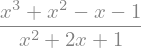

In [3]:
y = (x**3 + x**2 - x - 1)/(x**2 + 2*x + 1)
y

- And we can apply operations, e.g., simplification

In [4]:
sympy.simplify(y)

#### Find the derivative of an expression

$$\frac{d}{dx} \sin(x) e^x$$

In [5]:
f = sympy.sin(x) * sympy.exp(x)
f

In [6]:
sympy.exp?

Init signature: sympy.exp(arg)
Docstring:     
The exponential function, :math:`e^x`.

Examples

>>> from sympy import exp, I, pi
>>> from sympy.abc import x
>>> exp(x)
exp(x)
>>> exp(x).diff(x)
exp(x)
>>> exp(I*pi)
-1

Parameters

arg : Expr

See Also

log
File:           ~\documents\inf201-h26-my-repo\.venv\lib\site-packages\sympy\functions\elementary\exponential.py
Type:           ExpMeta
Subclasses:     

In [7]:
df = sympy.diff(f, x)
df

#### Find the integral of an expression

$$\int e^x\sin x + e^x \cos x dx$$

In [8]:
sympy.integrate(df, x)

#### Solve equations

- By default, SymPy assumes that the expression should be zero

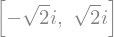

In [9]:
sympy.solve(x**2 + 2, x)

- If the right hand side is not zero, we need to use `Eq`

In [10]:
eq = sympy.Eq(x**2 + x, 3)
eq

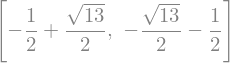

In [11]:
sympy.solve(eq, x)

- Using `solveset()` we can obtain all solutions

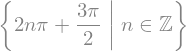

In [12]:
sympy.solveset(sympy.sin(x) + 1, x)

- This is just a little taste of what SymPy can do
- Some other features: 
    - Linear algebra (working with matrices)
    - sympy.physics (modeling physical systems such as pendulums)

In [13]:
sympy.init_printing(use_latex=False)  # Turn of LaTex printing for the rest of the notebook

### SciPy: A package for scientific computing with Python

- Builds on NumPy
- [User Guide](https://scipy.github.io/devdocs/tutorial/index.html#user-guide)
- Components
    - Special functions (scipy.special)
    - Integration (scipy.integrate)
    - Optimization (scipy.optimize)
    - Interpolation (scipy.interpolate)
    - Fourier Transforms (scipy.fft)
    - Signal Processing (scipy.signal)
    - Linear Algebra (scipy.linalg)
    - Sparse eigenvalue problems with ARPACK
    - Compressed Sparse Graph Routines (scipy.sparse.csgraph)
    - Spatial data structures and algorithms (scipy.spatial)
    - Statistics (scipy.stats)
    - Multidimensional image processing (scipy.ndimage)

### A selection of SciPy examples
- For a more complex example, see thee_body_problem.ipynb where we use SciPy methods to estimate solutions for the three-body problem in physics

#### Solving equations with no algebraic solution
- [`root_scalar`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.root_scalar.html#scipy.optimize.root_scalar) from `scipy.optimize` offers a selection of methods for finding the real root of a scalar function,<br>i.e. the $x$ where $f(x) = 0$
    - If no method is stated, SciPy will select the most appropriate one based on a fixed decision tree
    - Can also specify a bracket (interval) to search
- We look at the equation<br> 
$cos(x) - x = 0$

In [14]:
import numpy as np
from scipy.optimize import root_scalar

sol = root_scalar(lambda x: np.cos(x) - x, bracket=[0, 1])
print(f"Root: {sol.root:.6f} | Converged: {sol.converged} | Method: {sol.method}")

Root: 0.739085 | Converged: True | Method: brentq


#### Constrained optimization
- Maximize the volume of a cylindrical can ($V = \pi r^2 h$) with a fixed surface area of $100\text{ cm}^2$
    - $2\pi r^2 + 2\pi r h = 100$
- `scipy.optimize.minimize` will minimize rather than maximize, which we can get around by minimizing the negative of the volume
- This method supports specifying `constraints` on the form 
    ```python
        {"type": "eq", "fun": <function>}  # "eq" here means equality
    ```
- The analytical solution here is $h = 2r$, so we can use this to compare
    - $h/r=2$

In [15]:
from scipy.optimize import minimize

# SciPy minimizes functions, so negate volume to maximize it
def neg_volume(x: np.ndarray) -> float:
    """Negative volume of cylinder where x[0] is the radius and x[1] is the height"""
    return -np.pi * x[0]**2 * x[1]

# Area constraint where area - 100 = 0
# x[0] is the radius and x[1] is the height
area_eq = {"type": "eq", "fun": lambda x: 2*np.pi*x[0]**2 + 2*np.pi*x[0]*x[1] - 100}

res = minimize(neg_volume, x0=[2.0, 2.0], bounds=[(0.1, None), (0.1, None)], constraints=area_eq)
r, h = res.x
print(f"Optimal r = {r:.3f} cm, h = {h:.3f} cm (h/r = {h/r:.3f})")

Optimal r = 2.303 cm, h = 4.607 cm (h/r = 2.000)


#### Definite and improper integrals

- Compute the Gaussian integral $\int_{-\infty}^{\infty} e^{-x^2}\,dx$
    - Should be $\sqrt{\pi}$ ([ref](https://en.wikipedia.org/wiki/Gaussian_integral))
    - This function has no elementary antiderivative
    - Infinite limits

In [16]:
from scipy.integrate import quad

val, err = quad(lambda x: np.exp(-x**2), -np.inf, np.inf)
print(f"Integral: {val:.6f} vs sqrt(pi) = {np.sqrt(np.pi):.6f} (est. error: {err:.1e})")

Integral: 1.772454 vs sqrt(pi) = 1.772454 (est. error: 1.4e-08)


#### Smooth interpolation and derivatives
- `CubicSpline` returns a callable object that behaves like a smooth mathematical function

In [18]:
from scipy.interpolate import CubicSpline

hours = np.array([0, 2, 5, 8, 12])
temp_c = np.array([14.0, 15.2, 21.8, 24.1, 18.5])

spline = CubicSpline(hours, temp_c)
print(f"Temp at 3.5 h: {spline(3.5):.2f} °C | Heating rate: {spline(3.5, 1):.2f} °C/h")

Temp at 3.5 h: 18.47 °C | Heating rate: 2.40 °C/h


#### Finding hidden frequencies in noise
- [Fast Fourier Transform](https://en.wikipedia.org/wiki/Fast_Fourier_transform)
- We create a noisy set of frequencies around the main frequencies $5 Hz$ and $22 Hz$
- `rfftfreq` returns the Discrete Fourier Transform sample frequencies
- See separate script for generating the plots

In [ ]:
from scipy.fft import rfft, rfftfreq

t = np.linspace(0, 2, 1000, endpoint=False)  # 500 Hz sampling
rng = np.random.default_rng(0)
signal = 1.5*np.sin(2*np.pi*5*t) + 0.8*np.sin(2*np.pi*22*t) + rng.normal(0, 1.0, len(t))

freqs = rfftfreq(len(t), d=t[1] - t[0])
amplitudes = np.abs(rfft(signal)) * 2 / len(t)
print("Dominant frequencies (Hz):", np.sort(freqs[np.argsort(amplitudes)[-2:]]))

<img src="rfft_visualization.png" width=60%>

#### Statistical hypothesis testing
- `scipy.stats` provides over 100 probability distributions (`stats.norm`, `stats.poisson`, `stats.expon`)<br>with uniform `.pdf()`, .`cdf()`, `.rvs()`, and `.fit()` methods
- Let's do a two-sample t-test

In [19]:
from scipy import stats

control = np.array([10.2, 9.8, 10.5, 10.1, 9.9, 10.3])
treated = np.array([11.4, 11.8, 11.1, 11.6, 12.0, 11.5])

t_stat, p_val = stats.ttest_ind(treated, control)
print(f"t = {t_stat:.2f}, p = {p_val:.5f}")

t = 8.63, p = 0.00001


#### Exact physical constants and unit conversions
- `scipy.constants` provides lots of constants and conversions

In [20]:
from scipy import constants

print(f"R = {constants.R:.4f} J/(mol·K) | N_A = {constants.Avogadro:.4e} 1/mol")
print(f"37 °C in Kelvin: {constants.convert_temperature(37, 'C', 'K'):.2f} K")

R = 8.3145 J/(mol·K) | N_A = 6.0221e+23 1/mol
37 °C in Kelvin: 310.15 K


### Limits of numerical precision

- Computers represent floating point numbers with a fixed number of digits
- Most used today
    - 64-bit floating point numbers (aka "doubles")
    - 53-bit significand $\implies$ ca. 16 digits
    - smallest and largest numbers ca. $10^{-308}$ and $10^{308}$
    - details defined in [IEEE754 Standard for Floating-Point Arithmetic](https://en.wikipedia.org/wiki/IEEE_754)
- Machine learning often uses lower precision to gain performance

#### Example

In [21]:
import math

math.exp(math.log(5))

4.999999999999999

The numerical error in this case is

In [22]:
math.exp(math.log(5)) - 5

-8.881784197001252e-16

- This is $-8.881784197001252\times 10^{-16}$
- Such errors are unavoidable and we need to handle them properly
- *Numerical mathematics* is a branch of mathematics that focuses on how to obtain reliable results efficiently even while working with limited precision

#### Machine precision `eps`

Machine precision is the smallest number for which `1 + x > 1` yields `True`.

In [23]:
x = 1.
while 1 + x > 1:
    x /= 2
print(2*x)

2.220446049250313e-16


- This is the typical machine precision for 64-bit floating point numbers with 53-bit significand.
$$(-1)^{\text{sign}} \times 1.\underbrace{b_1 b_2 \dots b_{52}}_{52\text{ stored bits}} \times 2^{\text{exponent}}$$
- It is equal to 

In [24]:
2**-52

2.220446049250313e-16

#### Critical cases

- Numerical precision is especially critical if we subtract 
- Assume $x\approx 1$, $y\approx 1$ and $x-y=10^{-10}$
    - Only 16 decimals for floats `x` and `y`
    - $\Longrightarrow$ only the first 6 decimals of `x-y` will be meaningful, the rest noise
- Possible solutions
    - Attempt to reformulate mathematical expressions
    - If possible, use suitable built in functions, e.g., `math.expm1(x)` or `np.expm1(x)` to compute<br>
    $e^x-1=x+\frac{x^2}{2!}+\frac{x^3}{3!}+\mathcal{O}(x^4)$, especially if $x\approx 0$
    - Carefully monitor results

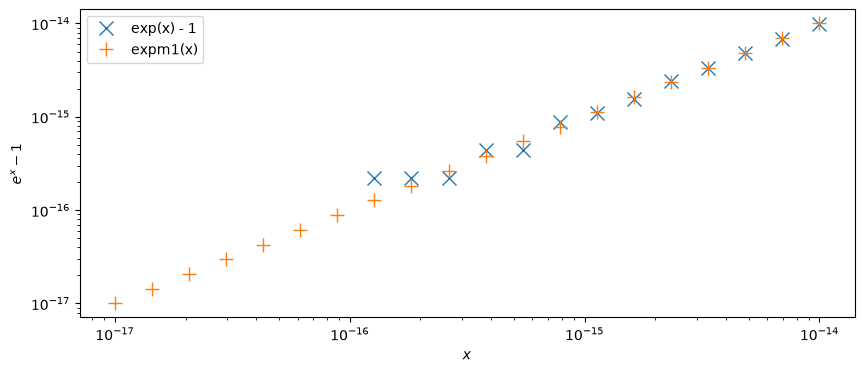

In [25]:
import matplotlib.pyplot as plt

x = np.logspace(-17, -14, 20)
y_exp = np.exp(x) - 1
y_expm1 = np.expm1(x)
plt.figure(figsize=(10, 4))
plt.loglog(x, y_exp, 'x', label='exp(x) - 1', ms=10)
plt.loglog(x, y_expm1, '+', label='expm1(x)', ms=10)
plt.xlabel('$x$')
plt.ylabel('$e^x-1$')
plt.legend()
plt.show()